# Milestone 3: Better model (compact)
**Goals:** ROC-AUC >= 0.78 and recall for defaulters >= 0.80 (beat the logistic-regression baseline) with side-table features and tree-based models.
Steps: 1 features -> 2 split + 5-fold CV of 3 algorithms -> 3 tune the best -> 4 hold-out check -> 5 summary.

## 1. Data and features (cleaning + side tables aggregated to one row per applicant)

## 2. Compare 3 algorithms with 5-fold stratified CV (ROC-AUC)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, precision_score, recall_score, ConfusionMatrixDisplay

DATA_DIR = Path("data/home-credit-default-risk")
SEED = 42

In [2]:
# Load and clean data:
def clean(df):
    df = df.copy()
    df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
    for col in ["CODE_GENDER", "ORGANIZATION_TYPE"]:
        df[col] = df[col].replace("XNA", np.nan)
    cat_cols = df.select_dtypes(exclude="number").columns
    df[cat_cols] = df[cat_cols].astype(object)
    df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
    df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"] / 365        # NaN stays NaN for the 365243 anomaly
    df["EMPLOYED_TO_AGE"] = df["YEARS_EMPLOYED"] / df["AGE_YEARS"]  # share of life spent in current job
    df = df.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED"])
    return df

app_train = clean(pd.read_csv(DATA_DIR / "application_train.csv"))

# new features: how heavy is the loan compared with income?
app_train["CREDIT_INCOME_RATIO"]  = app_train["AMT_CREDIT"]  / app_train["AMT_INCOME_TOTAL"]
app_train["ANNUITY_INCOME_RATIO"] = app_train["AMT_ANNUITY"] / app_train["AMT_INCOME_TOTAL"]
app_train["CREDIT_TERM"]          = app_train["AMT_ANNUITY"] / app_train["AMT_CREDIT"]
app_train["EXT_SOURCE_MEAN"]      = app_train[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
print(app_train.shape)

(307511, 128)


In [3]:
# Cell 3 adds information from the other tables: The problem is that application_train has one row per applicant,
#  while the side tables have many rows per applicant: one per old loan, one per monthly payment, and so on.
#  Cell 3 summarizes each side table down to one row per applicant, then merges it in.
# That extra history is the main reason the model in 07 should beat the baseline.
def aggregate(df, prefix):
    """One row per applicant: count + mean/max/sum of every numeric column."""
    num = df.select_dtypes("number").drop(columns=["SK_ID_PREV", "SK_ID_BUREAU"], errors="ignore")  # IDs are not features
    feat = num.groupby("SK_ID_CURR").agg(["mean", "max", "sum"])
    feat.columns = [f"{prefix}_{col}_{stat}" for col, stat in feat.columns]  # The prefix shows which table it came from e.g. BUR_AMT_CREDIT_SUM_mean
    feat[f"{prefix}_COUNT"] = df.groupby("SK_ID_CURR").size()   # number of records per applicant
    return feat.reset_index() # This turns SK_ID_CURR from the index back into a normal column so it can be merged.

inst = pd.read_csv(DATA_DIR / "installments_payments.csv")
inst["LATE_DAYS"]  = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]           # > 0 = paid late
inst["PAID_RATIO"] = inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan)  # < 1 = paid too little

bureau = aggregate(pd.read_csv(DATA_DIR / "bureau.csv"), "BUR")
prev   = aggregate(pd.read_csv(DATA_DIR / "previous_application.csv"), "PREV")
pos    = aggregate(pd.read_csv(DATA_DIR / "POS_CASH_balance.csv"), "POS")
cc     = aggregate(pd.read_csv(DATA_DIR / "credit_card_balance.csv"), "CC")
inst   = aggregate(inst, "INST")

for feat in [bureau, prev, pos, cc, inst]:
    app_train = app_train.merge(feat, on="SK_ID_CURR", how="left")  # left: keep every applicant
print(app_train.shape)

(307511, 325)


In [4]:
X = app_train.drop(columns=["TARGET", "SK_ID_CURR"]).replace([np.inf, -np.inf], np.nan)  # ratios can divide by 0
y = app_train["TARGET"]
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X.shape, f"default rate: {y.mean():.2%}")

(307511, 323) default rate: 8.07%


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
prep = make_column_transformer(
    (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), make_column_selector(dtype_exclude="number")),
    remainder="passthrough", verbose_feature_names_out=False) # lets the numeric columns through unchanged
tree_prep = lambda: make_pipeline(prep, SimpleImputer(strategy="median"))

models = {
    "RandomForest": make_pipeline(tree_prep(), RandomForestClassifier(100, min_samples_leaf=20, max_samples=0.3, class_weight="balanced", n_jobs=-1, random_state=SEED)),
    "ExtraTrees": make_pipeline(tree_prep(), ExtraTreesClassifier(100, min_samples_leaf=20, bootstrap=True, max_samples=0.3, class_weight="balanced", n_jobs=-1, random_state=SEED)),
}
# HGB handles NaN itself: ordinal-encode categoricals and tell it which columns are categorical
cat_cols = X_dev.select_dtypes(exclude="number").columns.tolist()
models["HistGradientBoosting"] = make_pipeline(
    make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), cat_cols),
                            remainder="passthrough", verbose_feature_names_out=False),
    HistGradientBoostingClassifier(categorical_features=list(range(len(cat_cols))), random_state=SEED))

cv_auc = {}
for name, m in models.items():
    s = cross_val_score(m, X_dev, y_dev, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_auc[name] = s.mean(); print(f"{name:22s} CV AUC = {s.mean():.4f} (+/- {s.std():.4f})")

RandomForest           CV AUC = 0.7621 (+/- 0.0026)
ExtraTrees             CV AUC = 0.7537 (+/- 0.0024)
HistGradientBoosting   CV AUC = 0.7771 (+/- 0.0013)


## 3. Tune the best model (randomized search, 5-fold CV)

In [6]:
best = max(cv_auc, key=cv_auc.get); print("Tuning:", best)
grids = {
    "HistGradientBoosting": {"histgradientboostingclassifier__learning_rate": [0.03, 0.05, 0.1],
                             "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
                             "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
                             "histgradientboostingclassifier__l2_regularization": [0, 1, 10],
                             "histgradientboostingclassifier__max_iter": [200, 400]},
    "RandomForest": {"randomforestclassifier__max_depth": [8, 12, None], "randomforestclassifier__min_samples_leaf": [10, 20, 50],
                     "randomforestclassifier__max_features": ["sqrt", 0.3]},
    "ExtraTrees": {"extratreesclassifier__max_depth": [8, 12, None], "extratreesclassifier__min_samples_leaf": [10, 20, 50],
                   "extratreesclassifier__max_features": ["sqrt", 0.3]},
}
search = RandomizedSearchCV(models[best], grids[best], n_iter=8, cv=cv, scoring="roc_auc", random_state=SEED, n_jobs=1, verbose=1)
search.fit(X_dev, y_dev)
print("best params:", search.best_params_); print(f"tuned CV AUC = {search.best_score_:.4f}")

Tuning: HistGradientBoosting
Fitting 5 folds for each of 8 candidates, totalling 40 fits
best params: {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 31, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.05, 'histgradientboostingclassifier__l2_regularization': 10}
tuned CV AUC = 0.7812


In [7]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[("hgb", search.best_estimator_),          # tuned gradient boosting
                ("rf",  models["RandomForest"]),
                ("et",  models["ExtraTrees"])],
    voting="soft",          # average the predicted probabilities (not the 0/1 votes)
    weights=[3, 1, 1])      # strongest model counts 3x

s = cross_val_score(ensemble, X_dev, y_dev, cv=cv, scoring="roc_auc", n_jobs=1)
print(f"Ensemble CV AUC = {s.mean():.4f} (+/- {s.std():.4f})  vs tuned HGB = {search.best_score_:.4f}")

Ensemble CV AUC = 0.7762 (+/- 0.0020)  vs tuned HGB = 0.7812


## 4. Goal check on the untouched hold-out set
Goals: **ROC-AUC >= 0.78** and **recall (defaulters) >= 0.80**.
The threshold for 80% recall is chosen on out-of-fold predictions of the dev set (not on the hold-out, to avoid leakage).

threshold = 0.058
hold-out AUC    = 0.7853  goal 0.78 -> OK
hold-out recall = 0.805   goal 0.80 -> OK
precision = 0.154 | applicants flagged = 42.3%


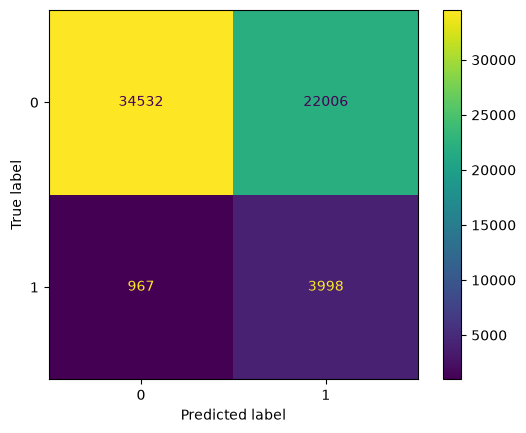

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, ConfusionMatrixDisplay
final = search.best_estimator_
oof = cross_val_predict(final, X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
thr = np.quantile(oof[y_dev == 1], 1 - 0.80)      # highest threshold that still catches 80% of dev defaulters

proba = final.predict_proba(X_test)[:, 1]; pred = (proba >= thr).astype(int)
auc, rec, prec = roc_auc_score(y_test, proba), recall_score(y_test, pred), precision_score(y_test, pred)
print(f"threshold = {thr:.3f}")
print(f"hold-out AUC    = {auc:.4f}  goal 0.78 -> {'OK' if auc >= 0.78 else 'not reached'}")
print(f"hold-out recall = {rec:.3f}   goal 0.80 -> {'OK' if rec >= 0.80 else 'not reached'}")
print(f"precision = {prec:.3f} | applicants flagged = {pred.mean():.1%}")
ConfusionMatrixDisplay.from_predictions(y_test, pred);

## 5. Summary
| Model | CV AUC | Hold-out AUC | Recall (class 1) | Precision (class 1) | % flagged |
|---|---|---|---|---|---|
| Logistic regression baseline (Milestone 2) | 0.7455 | 0.7487 | 0.675 | 0.161 | 34% |
| Tuned HistGradientBoosting | 0.7812 | **0.7853** | **0.805** | 0.154 | 42.3% |
| **Goal** | | **0.78** ✅ | **0.80** ✅ | | |

**Why is it better?** 197 side-table features (credit history at other banks, earlier
applications, payment delays), ratio features (credit/income, annuity/income), and a
non-linear gradient-boosting model that handles missing values natively.
Comparison: RF 0.762, ExtraTrees 0.754, HGB 0.777 → tuned HGB 0.781 (CV).
A soft-voting ensemble did not help (0.776).

**Trade-off:** to catch 80% of defaulters (threshold 0.058), 42% of applicants are
flagged; precision 15.4% ≈ 2× the base rate. Flagged = manual review, not rejection.

**Next steps:** feature importance, error analysis, slides (Milestone 4).